___
# <font color= #bbc28d> **EDA y preparación de datos** </font>
#### <font color= #53686c> `Proyecto final · Análisis Exploratorio`</font>
- <Strong> Diana Valdivia </Strong> · ITESO

___

Antes de entrenar nada hay que **entender los datos**. Revisaremos las fotos de maíz de PlantVillage y dejaremos listo todo lo que necesitan los modelos.

**Preguntas que responde:**
1. ¿Están bien las imágenes (tamaño, color, duplicados exactos) y cómo está el balance de clases?
2. ¿El fondo de la foto delata la clase?
3. ¿Hay hojas repetidas que podrían inflar las métricas si caen en train y test?
4. ¿Ayuda la versión `segmented` (sin fondo)?
5. ¿Cómo se arman los recortes y el split para que la evaluación sea honesta?

**Lo que sale de aquí:** `split_v1.csv` (a qué conjunto va cada imagen), `patch_index_v1.csv` (qué recortes se pueden usar) y las imágenes segmentadas en S3.

In [1]:
!pip install -q boto3 matplotlib scipy scikit-learn pillow pandas numpy


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


# **<font color= #7aa8a7> Configuración y funciones de apoyo </font>**
Se definen la región, el bucket, las clases y las rutas de trabajo. Después, unas funciones que se usan varias veces:
- `dark_frac`: qué fracción de la imagen es casi negra (mide cuánto fondo negro tiene).
- `bg_mask`: máscara del fondo negro. Solo cuenta regiones oscuras **grandes**, para no confundir una lesión oscura con fondo.

In [ ]:
import hashlib, json, re, shutil, subprocess
from pathlib import Path

import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy import ndimage as ndi

# Config general
REGION = "us-east-1"
ACCOUNT_ID = boto3.client("sts").get_caller_identity()["Account"]
BUCKET = f"sagemaker-maize-disease-{ACCOUNT_ID}-{REGION}"
S3_PREFIX = "maize/raw" # variante color
S3_PREFIX_SEG = "maize/raw_segmented" # variante segmentada
s3 = boto3.client("s3", region_name=REGION)

# Clases: carpeta original del repo -> nombre limpio
CLASS_MAP = {
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": "gray_leaf_spot",
    "Corn_(maize)___Common_rust_": "common_rust",
    "Corn_(maize)___Northern_Leaf_Blight": "northern_blight",
    "Corn_(maize)___healthy": "healthy",
}
EXTS = {".jpg", ".jpeg", ".png"}

# Rutas locales de la instancia
WORK = Path.home() / "maize_work"
CLEAN = WORK / "raw"                  # copia local de color
SEG_REPO = WORK / "PlantVillage-seg"  # clon parcial del repo (solo raw/segmented de maíz)
SEG = WORK / "raw_segmented"          # segmented con los mismos nombres de archivo que color
WORK.mkdir(exist_ok=True)

In [3]:
# Funciones de apoyo
def run(cmd, cwd=None):
    """Ejecuta un comando de shell y falla si devuelve error."""
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=cwd, check=True)

def dark_frac(p, thr=20):
    """Fracción de píxeles casi negros (max(R,G,B) < thr). Mide cuánto 'fondo negro' tiene una imagen."""
    a = np.asarray(Image.open(p).convert("RGB"))
    return (a.max(axis=2) < thr).mean()

def bg_mask(img, thr=30, min_px=150, grow=3):
    """Máscara de fondo negro. Solo cuentan regiones oscuras GRANDES (min_px) para no tomar
    sombras pequeñas ni lesiones oscuras por fondo, y se dilata 'grow' px para cubrir el halo del borde."""
    a = np.asarray(img.convert("RGB"))
    dark = a.max(axis=2) < thr
    lab, n = ndi.label(dark)
    sizes = ndi.sum(dark, lab, range(1, n + 1))
    keep = np.isin(lab, [i + 1 for i, s in enumerate(sizes) if s >= min_px])
    return ndi.binary_dilation(keep, iterations=grow)

def dhash_bits(img, size=16):
    """Hash perceptual 'diferencia' de 16x16 = 256 bits. (El de 8x8 era demasiado grueso: ver sección 4.)"""
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)   # tabla de bits en 1 por byte

# **<font color= #7aa8a7> 1. Inventario y control de calidad </font>**
Se arma una tabla `df` con una fila por imagen: ruta, clase, tamaño, modo de color, peso y un **hash md5** (huella exacta del archivo). Con ella se revisa que los datos estén sanos antes de seguir.

In [4]:
# Si no hay copia local de color, bajarla de S3
if not CLEAN.exists() or not any(CLEAN.rglob("*")):
    run(["aws", "s3", "sync", f"s3://{BUCKET}/{S3_PREFIX}/", str(CLEAN),
         "--region", REGION, "--only-show-errors"])

rows = []
for label in sorted(CLASS_MAP.values()):
    for f in sorted((CLEAN / label).iterdir()):
        with Image.open(f) as im:
            w, h, mode = im.width, im.height, im.mode
        rows.append(dict(
            path=str(f), s3_key=f"{S3_PREFIX}/{label}/{f.name}", label=label,
            filename=f.name, width=w, height=h, mode=mode,
            kb=f.stat().st_size / 1024,
            md5=hashlib.md5(f.read_bytes()).hexdigest(),
        ))
df = pd.DataFrame(rows)
print(df.shape)
df.head()

(3852, 9)


,path,s3_key,label,filename,width,height,mode,kb,md5
0,/home/ec2-user/maize_work/raw/common_rust/RS_R...,maize/raw/common_rust/RS_Rust 1563.JPG,common_rust,RS_Rust 1563.JPG,256,256,RGB,11.187500,87cebb57af923340b4cb9c021f844003
1,/home/ec2-user/maize_work/raw/common_rust/RS_R...,maize/raw/common_rust/RS_Rust 1564.JPG,common_rust,RS_Rust 1564.JPG,256,256,RGB,11.541016,0ef702cfef4dd60d28ec49344e2dcc33
2,/home/ec2-user/maize_work/raw/common_rust/RS_R...,maize/raw/common_rust/RS_Rust 1565.JPG,common_rust,RS_Rust 1565.JPG,256,256,RGB,14.747070,c06af4cd7cfde4c9d49833d72f365028
3,/home/ec2-user/maize_work/raw/common_rust/RS_R...,maize/raw/common_rust/RS_Rust 1566.JPG,common_rust,RS_Rust 1566.JPG,256,256,RGB,15.799805,88156e12bd81d86b5488f05421cc77fe
4,/home/ec2-user/maize_work/raw/common_rust/RS_R...,maize/raw/common_rust/RS_Rust 1567.JPG,common_rust,RS_Rust 1567.JPG,256,256,RGB,16.091797,e9558385385f08835f84daabfc3a03dd


Tamaños (ancho x alto):
width  height
256    256       3852
dtype: int64 

Modos de color:
mode
RGB    3852
Name: count, dtype: int64 

Peso por imagen (KB):
count    3852.0
mean       13.2
std         3.0
min         3.8
25%        11.4
50%        13.4
75%        15.2
max        23.5
Name: kb, dtype: float64 

Duplicados exactos (mismo md5): 0 imágenes

Imágenes por clase:
                    n     %
label                      
common_rust      1192  30.9
healthy          1162  30.2
northern_blight   985  25.6
gray_leaf_spot    513  13.3


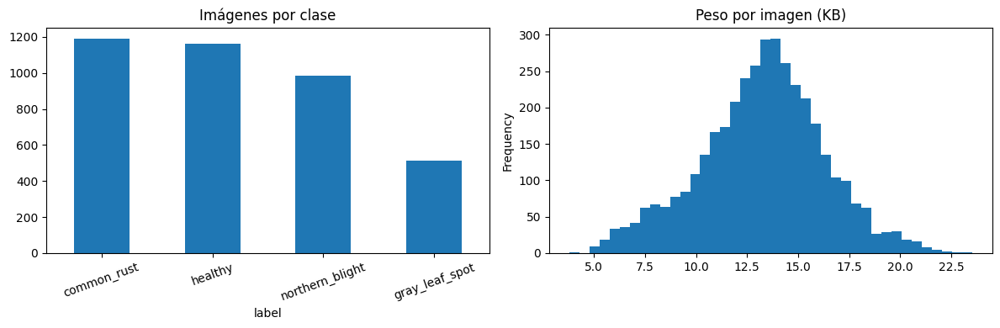

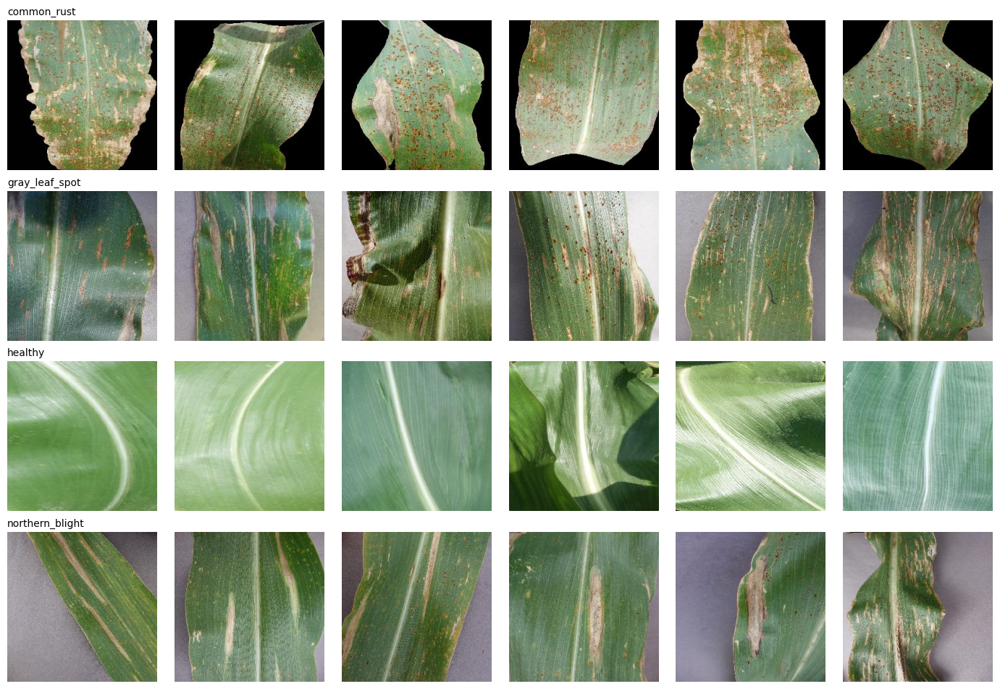

In [6]:
print("Tamaños (ancho x alto):")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(), "\n")
print("Modos de color:")
print(df["mode"].value_counts(), "\n")
print("Peso por imagen (KB):")
print(df["kb"].describe().round(1), "\n")
print("Duplicados exactos (mismo md5):", df.duplicated("md5", keep=False).sum(), "imágenes")
print("\nImágenes por clase:")
print(pd.DataFrame({"n": df["label"].value_counts(),
                    "%": (df["label"].value_counts(normalize=True) * 100).round(1)}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["label"].value_counts().plot.bar(ax=ax[0], title="Imágenes por clase", rot=20)
df["kb"].plot.hist(bins=40, ax=ax[1], title="Peso por imagen (KB)")
plt.tight_layout(); plt.show()

# 6 ejemplos al azar por clase
labels = sorted(df["label"].unique())
fig, axes = plt.subplots(len(labels), 6, figsize=(14, 2.4 * len(labels)))
for r, lab in enumerate(labels):
    for c, p in enumerate(df[df.label == lab].sample(6, random_state=1)["path"]):
        axes[r, c].imshow(Image.open(p)); axes[r, c].axis("off")
    axes[r, 0].set_title(lab, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

**Qué encontramos:**
- Las **3,852 imágenes** miden 256×256 y son RGB, así que no hace falta unificar tamaños.
- **0 duplicados exactos** (mismo md5). Esto solo detecta archivos **idénticos**; las fotos *casi* iguales (giradas o recortadas) se procesan de forma distinta mas abajo en este notebook.
- Hay **desbalance**: `gray_leaf_spot` es solo el 13.3% del total, contra ~30% de `common_rust` y `healthy`.

Por eso se reportará **macro-F1** y no solo accuracy.

**Observación visual:** `color` **no** tiene un fondo uniforme, como suponía la propuesta original.
- `common_rust`: fondo **negro** (la hoja ya viene recortada).
- `gray_leaf_spot` y `northern_blight`: **telón gris/morado** real, a veces con sombras duras.
- `healthy`: acercamientos de un trozo de hoja, sin fondo visible.

Es decir, cada clase tiene un "tipo de fondo" distinto.

# **<font color= #7aa8a7> 2. ¿El fondo delata la clase? </font>**
Al ver las fotos se nota que las clases no se parecen en el fondo. Si un modelo aprende "fondo negro = roya" en lugar de reconocer la enfermedad, tendría buenas métricas **por la razón equivocada** y fallaría con fotos reales de campo. Se mide cuántas imágenes de cada clase tienen fondo negro.

% de imágenes con fondo negro por clase:
label
common_rust        99.7
gray_leaf_spot      2.3
healthy             0.0
northern_blight     0.2
Name: black_bg, dtype: float64

Fracción de píxeles casi negros (mediana por clase):
label
common_rust        0.304
gray_leaf_spot     0.000
healthy            0.000
northern_blight    0.000
Name: dark_frac, dtype: float64


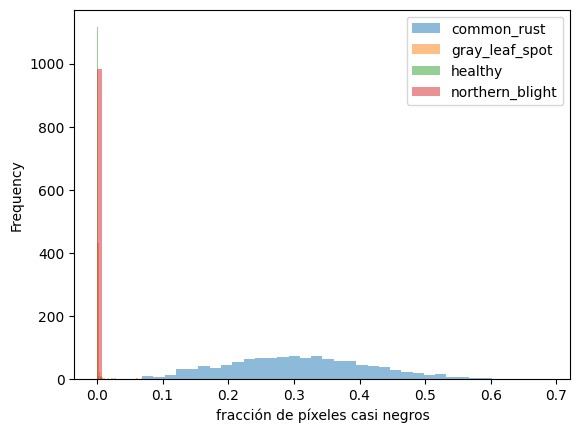

In [7]:
# ¿Cuánto fondo negro tiene cada clase?
df["dark_frac"] = [dark_frac(p) for p in df["path"]]
df["black_bg"] = df["dark_frac"] > 0.05

print("% de imágenes con fondo negro por clase:")
print((df.groupby("label")["black_bg"].mean() * 100).round(1))
print("\nFracción de píxeles casi negros (mediana por clase):")
print(df.groupby("label")["dark_frac"].median().round(3))

df.groupby("label")["dark_frac"].plot.hist(bins=40, alpha=0.5, legend=True)
plt.xlabel("fracción de píxeles casi negros"); plt.show()

**Resultado:** 99.7% de `common_rust` tiene fondo negro; `gray_leaf_spot` 2.3%, `northern_blight` 0.2%, `healthy` 0%.
El fondo negro es casi un identificador de la roya.

**Máscara de fondo.** Para medir el fondo con más cuidado se construye una máscara (se agranda un poco para cubrir el borde borroso) y el fondo se reemplaza por gris, solo para ver si la máscara está bien. Luego se calcula `bg_frac`, la fracción de cada imagen que es fondo.

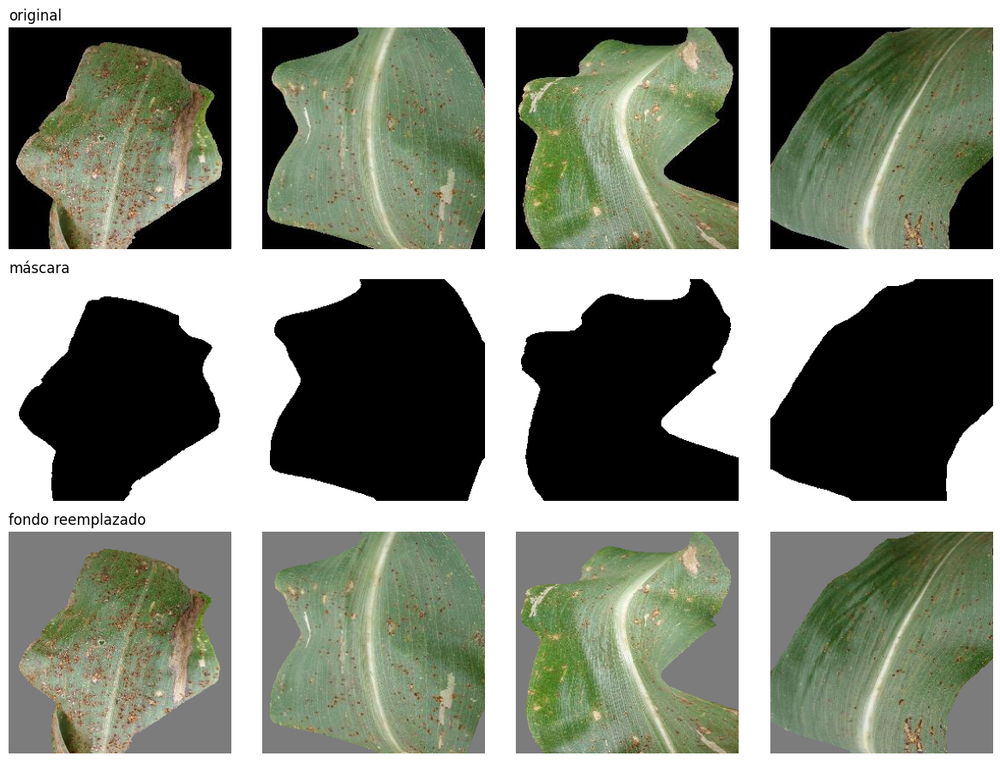

                  count   mean    std  min    25%    50%   75%    max
label                                                                
common_rust      1192.0  0.334  0.113  0.0  0.255  0.331  0.41  0.714
gray_leaf_spot    513.0  0.012  0.031  0.0  0.000  0.000  0.00  0.270
healthy          1162.0  0.001  0.007  0.0  0.000  0.000  0.00  0.116
northern_blight   985.0  0.001  0.010  0.0  0.000  0.000  0.00  0.291


In [8]:
# Crear una máscara de fondo mas limpia
samples = df[df.label == "common_rust"].sample(4, random_state=3)["path"]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for c, p in enumerate(samples):
    im = Image.open(p)
    gray = np.asarray(im.convert("RGB")).copy()
    gray[bg_mask(im)] = (124, 124, 124)                       # fondo reemplazado por gris
    axes[0, c].imshow(im); axes[1, c].imshow(bg_mask(im), cmap="gray"); axes[2, c].imshow(gray)
    for r in range(3): axes[r, c].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("máscara", loc="left")
axes[2, 0].set_title("fondo reemplazado", loc="left")
plt.tight_layout(); plt.show()

df["bg_frac"] = [bg_mask(Image.open(p)).mean() for p in df["path"]]
print(df.groupby("label")["bg_frac"].describe().round(3))

La fracción de fondo en `common_rust` es en promedio **0.33**, mientras que en las otras clases es casi **0** (0.012 en `gray_leaf_spot` y 0.001 en las demás). La máscara separa muy bien a la roya del resto.

Ahora busquemos las **excepciones**: royas sin fondo y otras clases con fondo, para entender qué son.

common_rust sin fondo: 3 | otras clases con fondo: 63
label
gray_leaf_spot     56
healthy             5
northern_blight     2


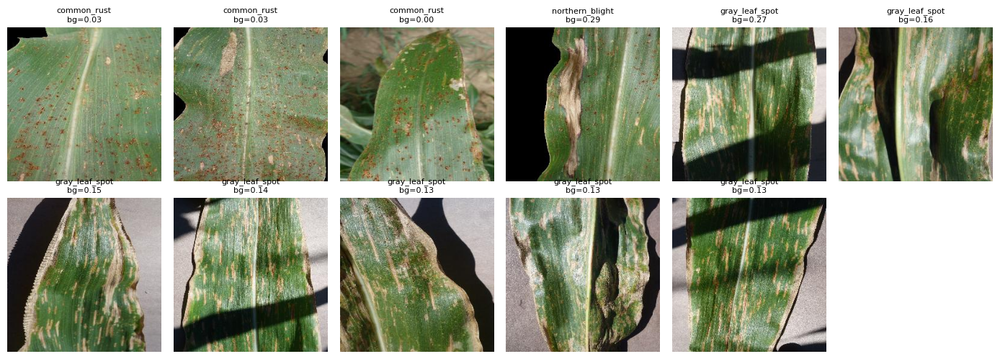

In [9]:
# ¿Cuáles son las excepciones?
a = df[(df.label == "common_rust") & (df.bg_frac < 0.05)]
b = df[(df.label != "common_rust") & (df.bg_frac > 0.05)].sort_values("bg_frac", ascending=False)
print(f"common_rust sin fondo: {len(a)} | otras clases con fondo: {len(b)}")
print(b["label"].value_counts().to_string())

sel = pd.concat([a.head(4), b.head(8)])
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, (_, row) in zip(axes.ravel(), sel.iterrows()):
    ax.imshow(Image.open(row["path"])); ax.axis("off")
    ax.set_title(f"{row['label']}\nbg={row['bg_frac']:.2f}", fontsize=8)
for ax in axes.ravel()[len(sel):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Resultado:** 63 imágenes no-roya "con fondo" (56 de `gray_leaf_spot`). Son sobre todo **sombras duras** que la máscara
toma por fondo, no fondos negros reales. Las sombras también podrían ser una pista que correlaciona con la clase, pero es un efecto menor
frente al negro de la roya.

### **<font color= #7aa8a7>Casi Duplicados y Grupos </font>**
PlantVillage tiene varias fotos de la misma hoja (giradas, volteadas, recortadas). Si una cae en train y otra
en test, el modelo "ya vio" la hoja y las métricas salen infladas. Se detectan con un hash perceptual y se agrupan; luego el split
manda **grupos completos** a un mismo conjunto.

**Desglose:**
1. Primer intento: hash 8×8 comparando entre *todas* las clases → 44 grupos con duplicados, **14 mezclaban clases**.
   Al verlos eran hojas distintas: un hash tan grueso confunde acercamientos `healthy` (poca textura) y el union-find
   encadena (si A≈B y B≈C junta a las tres), lo que dio un grupo de 24.
2. Corrección: hash **16×16** y comparar **solo dentro de cada clase** (un duplicado real nunca cambia de clase).
   Con eso los grupos mixtos son 0 por construcción.

**Hash perceptual (dHash 16×16).** Cada imagen se convierte en una huella de 256 bits que describe sus cambios de brillo. Se calcula en las **8 orientaciones** (4 giros × espejo) para detectar la misma hoja girada o volteada.

Se comparan las huellas **solo dentro de cada clase** y se cuenta cuántos pares quedan por debajo de varios umbrales de distancia.

In [ ]:
# Hash 16x16 de cada imagen en las 8 orientaciones (4 giros x espejo)
H = np.zeros((len(df), 8, 32), dtype=np.uint8)
for i, p in enumerate(df["path"]):
    with Image.open(p) as im:
        im = im.convert("RGB")
        k = 0
        for base in (im, ImageOps.mirror(im)):
            for r in range(4):
                H[i, k] = dhash_bits(base.rotate(90 * r, expand=True)); k += 1

# Todos los pares MISMA CLASE con distancia de Hamming <= 48 
MAX_D = 48
pairs = [] 
for lab in df["label"].unique():
    idx = np.where(df["label"].values == lab)[0]
    for k in range(len(idx) - 1):
        d = POP[H[idx[k], 0] ^ H[idx[k + 1:]]].sum(-1).min(axis=1)
        for j in np.where(d <= MAX_D)[0]:
            pairs.append((int(d[j]), int(idx[k]), int(idx[k + 1 + j])))
pairs.sort()

print("Pares encontrados según el umbral:")
for t in (8, 16, 24, 32, 40, 48):
    print(f"  THRESH={t:>2}: {sum(d <= t for d, _, _ in pairs)} pares")

Pares encontrados según el umbral:
  THRESH= 8: 1 pares
  THRESH=16: 3 pares
  THRESH=24: 5 pares
  THRESH=32: 8 pares
  THRESH=40: 10 pares
  THRESH=48: 17 pares


Mientras más alto el umbral, más pares aparecen (de 1 con umbral 8 a 17 con umbral 48), pero también es más probable que sean hojas distintas que solo se parecen. De forma visual veamos cuáles son pares reales.

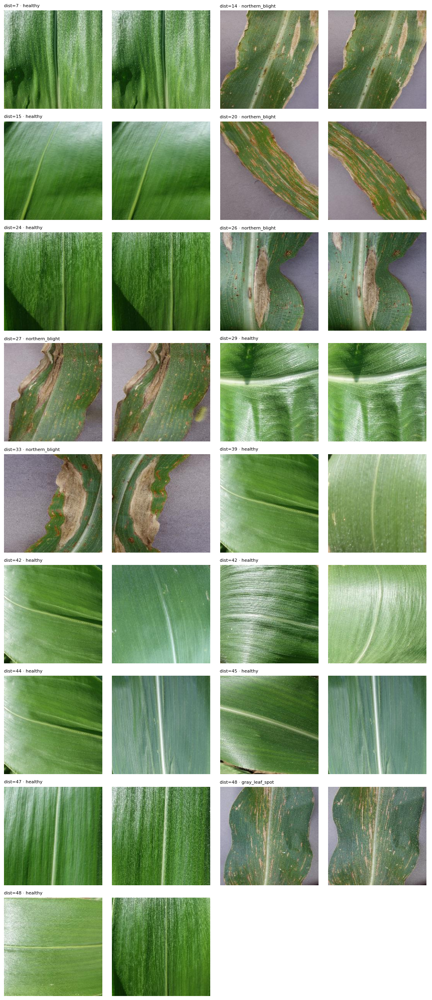

In [ ]:
# Pares debajo del umbral
if pairs:
    ncols = 2                                   # 2 pares por fila = 4 imágenes
    nrows = int(np.ceil(len(pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols * 2, figsize=(11, 2.8 * nrows))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for n, (d, i, j) in enumerate(pairs):
        r, c = divmod(n, ncols)
        for k, x in enumerate((i, j)):
            axes[r, c * 2 + k].imshow(Image.open(df.loc[x, "path"]))
        axes[r, c * 2].set_title(f"dist={d} · {df.loc[i, 'label']}", fontsize=8, loc="left")
    plt.tight_layout(); plt.show()
else:
    print("No hay pares por debajo del umbral.")

### **<font color= #7aa8a7>Variante `Segmented`</font>**

El repo también trae `raw/segmented`, con el fondo removido (negro) en las hojas. Si el negro aparece en las clases enfermas,
el fondo deja de delatar *solo* a la roya.

**Cómo se empareja con `color`:** por nombre de archivo, quitando el prefijo UUID y el sufijo `_final_masked`.

**NOTA**: `common_rust`: en `color` el archivo se llama `RS_Rust 1933.JPG` (sin UUID) y en `segmented`
`007f6e89-…___RS_Rust 1933_final_masked.jpg`. Por eso `key()` quita el UUID **en ambos lados** antes de comparar.

Se baja del repositorio solo la carpeta `raw/segmented` de las 4 clases, igual que antes:

In [14]:
# Descarga parcial del repo 
if not (SEG_REPO / "raw" / "segmented").exists():
    if SEG_REPO.exists():
        shutil.rmtree(SEG_REPO)
    run(["git", "clone", "--filter=blob:none", "--no-checkout", "--depth", "1",
         "https://github.com/spMohanty/PlantVillage-Dataset.git", str(SEG_REPO)])
    run(["git", "sparse-checkout", "init", "--cone"], cwd=SEG_REPO)
    run(["git", "sparse-checkout", "set", *[f"raw/segmented/{f}" for f in CLASS_MAP]], cwd=SEG_REPO)
    run(["git", "checkout", "master"], cwd=SEG_REPO)

**Emparejamiento color ↔ segmented.** Se une cada imagen `color` con su versión `segmented` usando la clave del nombre (`key()`), y se copia la segmentada con el **mismo nombre** que la de color.

In [ ]:
UUID = re.compile(r"^[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}___", re.I)

def key(name):
    """Clave de emparejamiento: sin UUID, sin '_final_masked', en minúsculas."""
    s = Path(name).stem.replace("_final_masked", "")
    return UUID.sub("", s).lower()

if SEG.exists():
    shutil.rmtree(SEG)

seg_map = {}   # (clase, nombre de archivo color) -> ruta segmentada
print(f"{'clase':<18}{'segmented':>10}{'emparejadas':>13}{'color sin par':>15}{'claves repetidas':>18}")
for orig, clean in CLASS_MAP.items():
    out = SEG / clean
    out.mkdir(parents=True, exist_ok=True)

    sub = df[df.label == clean]
    ckeys = sub["filename"].map(key)
    by_key = dict(zip(ckeys, sub["filename"]))
    rep = int(ckeys.duplicated().sum())     # colisiones al quitar el UUID

    n = m = 0
    for f in (SEG_REPO / "raw" / "segmented" / orig).iterdir():
        if f.suffix.lower() not in EXTS:
            continue
        n += 1
        k = key(f.name)
        if k in by_key:
            color_name = by_key[k]
            dst = out / (Path(color_name).stem + f.suffix)
            shutil.copy2(f, dst)
            seg_map[(clean, color_name)] = str(dst)
            m += 1
    print(f"{clean:<18}{n:>10}{m:>13}{len(sub) - m:>15}{rep:>18}")

df["seg_path"] = [seg_map.get((l, f), "") for l, f in zip(df["label"], df["filename"])]
assert (df["seg_path"] != "").all(), "Hay imágenes de color sin su versión segmentada"
print("\nTodas las imágenes de color tienen su par segmentado.")

clase              segmented  emparejadas  color sin par  claves repetidas
gray_leaf_spot           513          513              0                 0
common_rust             1192         1192              0                 0
northern_blight          985          985              0                 0
healthy                 1162         1162              0                 0

Todas las imágenes de color tienen su par segmentado.


Las 3,852 imágenes de color tienen su par segmentado y no hay claves repetidas. Esto permite usar **el mismo split para las dos variantes**, que es lo que hace limpia la comparación.

**Grupos de duplicados.** Los pares similares se unen con *union-find*: si A≈B y B≈C, las tres quedan en un grupo. Cada grupo recibe un número, y el split mandará **grupos completos** a un mismo conjunto.

In [ ]:
def dhash_bits(img, size=16):
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())   # 32 bytes = 256 bits

def orientations(img):
    out = []
    for base in (img, ImageOps.mirror(img)):
        for k in range(4):
            out.append(base.rotate(90 * k, expand=True))
    return out

H = np.zeros((len(df), 8, 32), dtype=np.uint8)
for i, p in enumerate(df["path"]):
    with Image.open(p) as im:
        im = im.convert("RGB")
        for o, v in enumerate(orientations(im)):
            H[i, o] = dhash_bits(v)

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

THRESH = 16 

parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

n_pairs = 0
for lab in df["label"].unique():
    idx = np.where(df["label"].values == lab)[0] # Solo en la misma clase
    for k in range(len(idx) - 1):
        i = idx[k]
        d = POP[H[i, 0] ^ H[idx[k + 1:]]].sum(-1).min(axis=1)
        for j in idx[k + 1:][d <= THRESH]:
            union(i, int(j)); n_pairs += 1

df["group"] = [find(i) for i in range(len(df))]
sizes = df.groupby("group").size()
multi = sizes[sizes > 1]
cross = df.groupby("group")["label"].nunique()

print(f"Pares similares: {n_pairs}")
print(f"Grupos totales: {len(sizes)} | con 2+ imágenes: {len(multi)}")
print(f"Imágenes en grupos con duplicados: {int(multi.sum())} de {len(df)}")
print("Tamaño de grupo más grande:", sizes.max())
print("Grupos con clases mezcladas:", int((cross > 1).sum()), "(debe ser 0)")
print("\nGrupos más grandes por clase:")
print(df.groupby("group").agg(n=("path", "size"), clase=("label", "first"))
        .sort_values("n", ascending=False).head(8))

Pares similares: 3
Grupos totales: 3849 | con 2+ imágenes: 3
Imágenes en grupos con duplicados: 6 de 3852
Tamaño de grupo más grande: 2
Grupos con clases mezcladas: 0 (debe ser 0)

Grupos más grandes por clase:
       n            clase
group                    
2360   2          healthy
3371   2  northern_blight
2051   2          healthy
2571   1          healthy
2570   1          healthy
2569   1          healthy
2568   1          healthy
2567   1          healthy


Solo hay **3 pares** (6 de 3,852 imágenes) y **0 grupos con clases mezcladas**. Son pocos, así que el riesgo de fuga de datos por duplicados es bajo, pero aun así se respetan los grupos al dividir.

# **<font color= #7aa8a7> 3. ¿Qué cambia con `segmented`? </font>**
Se compara cuánto negro tiene cada clase en `color` y en `segmented`, y se ven ejemplos lado a lado.

Fracción de negro (mediana por clase), color vs segmented:
                 color  segmented
label                            
common_rust      0.304      0.302
gray_leaf_spot   0.000      0.263
healthy          0.000      0.000
northern_blight  0.000      0.268


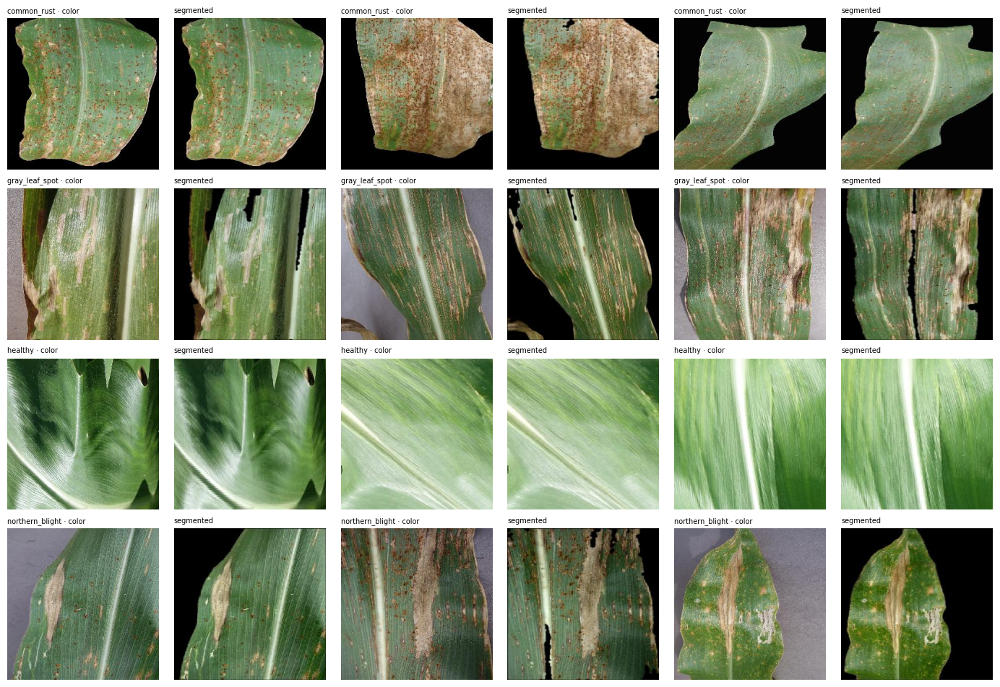

In [ ]:
df["dark_seg"] = [dark_frac(p) for p in df["seg_path"]]
print("Fracción de negro (mediana por clase), color vs segmented:")
print(pd.DataFrame({"color": df.groupby("label")["dark_frac"].median(),
                    "segmented": df.groupby("label")["dark_seg"].median()}).round(3))

labs = sorted(df.label.unique())
fig, axes = plt.subplots(len(labs), 6, figsize=(14, 2.4 * len(labs)))
for r, lab in enumerate(labs):
    for c, (_, row) in enumerate(df[df.label == lab].sample(3, random_state=5).iterrows()):
        axes[r, c * 2].imshow(Image.open(row["path"]))
        axes[r, c * 2 + 1].imshow(Image.open(row["seg_path"]))
        axes[r, c * 2].set_title(f"{lab} · color", fontsize=7, loc="left")
        axes[r, c * 2 + 1].set_title("segmented", fontsize=7, loc="left")
    for a in axes[r]:
        a.axis("off")
plt.tight_layout(); plt.show()

En `segmented`, `gray_leaf_spot` y `northern_blight` pasan de ~0 a **~0.26 de negro** (mediana), parecido a `common_rust` (0.30). Con esto **el negro ya no identifica solo a la roya**.

Pero `healthy` sigue en 0: sus fotos son acercamientos a un trozo de hoja sin fondo. Es decir, en `segmented` "hay negro" ahora significa "no es sana", una pista que también hay que quitar.

# **<font color= #7aa8a7> 4. Probar la teoría del fondo </font>**
Establecemos la siguiente hipótesis: *"si la imagen tiene fondo, es roya"*. Si esta regla ya funciona muy bien, el fondo es un atajo peligroso.

In [18]:
# Probar teoría fondo negro - roya
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, f1_score, recall_score

y = df["label"].values
g = df["group"].values
labs = sorted(set(y))

rule = np.where(df["bg_frac"] > 0.05, "common_rust", "otra")
is_rust = y == "common_rust"
tp = ((rule == "common_rust") & is_rust).sum()
print("REGLA 'hay fondo -> roya':")
print(f"  precisión roya: {tp / (rule == 'common_rust').sum():.3f} | recall roya: {tp / is_rust.sum():.3f}")

REGLA 'hay fondo -> roya':
  precisión roya: 0.950 | recall roya: 0.997


**Resultado:** precisión 0.950, recall 0.997. Una sola condición sobre el fondo acierta 997 de cada 1,000 royas.
Los falsos positivos son sobre todo las sombras de `gray_leaf_spot`. **El sesgo del fondo es real en `color`.**

# **<font color= #7aa8a7>Cinco Experimentos con RFs</font>**

| Experimento | Qué ve el modelo | Qué mide |
|---|---|---|
| A. `color`, imagen completa | todo, incluido el fondo | rendimiento "con trampa" |
| B. `color`, sin píxeles negros | hoja + telón gris (el negro se descarta) | quita el fondo de la roya, pero **no** el de las otras |
| C. `segmented`, sin píxeles negros | solo tejido de hoja en las tres clases enfermas | el caso más limpio disponible |
| D. `color`, **solo esquinas** | únicamente el fondo | cuánto delata la clase el fondo en `color` |
| E. `segmented`, **solo esquinas** | únicamente el fondo | lo mismo en `segmented` |

In [19]:
def _hist(hsv):
    return np.concatenate([np.histogram(hsv[:, c], bins=16, range=(0, 256), density=True)[0] for c in range(3)])

def feat_full(p):
    """Histograma HSV de toda la imagen."""
    return _hist(np.asarray(Image.open(p).convert("RGB").convert("HSV")).reshape(-1, 3))

def feat_leaf(p, thr=20):
    """Histograma HSV solo de píxeles NO negros."""
    im = Image.open(p).convert("RGB")
    rgb = np.asarray(im).reshape(-1, 3)
    hsv = np.asarray(im.convert("HSV")).reshape(-1, 3)
    keep = rgb.max(axis=1) >= thr
    return _hist(hsv[keep] if keep.sum() > 100 else hsv)

def feat_corners(p, s=32):
    """Histograma HSV de las 4 esquinas (s x s): lo que 've' un modelo que solo mira el fondo."""
    a = np.asarray(Image.open(p).convert("RGB").convert("HSV"))
    patches = [a[:s, :s], a[:s, -s:], a[-s:, :s], a[-s:, -s:]]
    return _hist(np.concatenate([q.reshape(-1, 3) for q in patches]))

rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=0)
cv = GroupKFold(n_splits=5)

experiments = {
    "A. color · imagen completa":      (feat_full,    "path"),
    "B. color · sin píxeles negros":   (feat_leaf,    "path"),
    "C. segmented · sin píxeles negros": (feat_leaf,  "seg_path"),
    "D. color · solo esquinas":        (feat_corners, "path"),
    "E. segmented · solo esquinas":    (feat_corners, "seg_path"),
}

results, confusions = [], {}
for name, (fn, col) in experiments.items():
    X = np.array([fn(p) for p in df[col]])
    pred = cross_val_predict(rf, X, y, groups=g, cv=cv)
    row = {"experimento": name,
           "accuracy": np.mean(pred == y),
           "macro-F1": f1_score(y, pred, average="macro")}
    for lab, r in zip(labs, recall_score(y, pred, labels=labs, average=None)):
        row[f"recall {lab}"] = r
    results.append(row)
    confusions[name] = pd.DataFrame(confusion_matrix(y, pred, labels=labs), index=labs, columns=labs)
    print("listo:", name)

res = pd.DataFrame(results).set_index("experimento").round(3)
print("\nAzar aproximado: 25% (clases iguales) a 31% (siempre la clase más grande)\n")
res

listo: A. color · imagen completa
listo: B. color · sin píxeles negros
listo: C. segmented · sin píxeles negros
listo: D. color · solo esquinas
listo: E. segmented · solo esquinas

Azar aproximado: 25% (clases iguales) a 31% (siempre la clase más grande)



,accuracy,macro-F1,recall common_rust,recall gray_leaf_spot,recall healthy,recall northern_blight
experimento,,,,,,
A. color · imagen completa,0.955,0.934,0.997,0.756,0.999,0.953
B. color · sin píxeles negros,0.954,0.934,0.994,0.768,0.999,0.949
C. segmented · sin píxeles negros,0.908,0.866,0.964,0.559,0.998,0.914
D. color · solo esquinas,0.937,0.908,0.998,0.667,0.999,0.932
E. segmented · solo esquinas,0.838,0.775,0.918,0.376,0.993,0.799


- **D (color, solo esquinas): 93.7% de accuracy.** Un modelo que **solo ve las esquinas**, es decir, solo el fondo y nada de la hoja, casi iguala al que ve la imagen completa (A: 95.5%). Esto confirma el atajo del fondo en `color`.
- **A y B son casi iguales** (0.934 de macro-F1 los dos): quitar el negro no cambia mucho porque las otras clases siguen teniendo su telón gris.
- **C (segmented, sin negro) baja a 0.866** de macro-F1 y **E (segmented, esquinas) cae a 0.775**: al quitar el fondo, el modelo tiene menos pistas fáciles. Es el resultado más cercano a "leer la enfermedad".
- `gray_leaf_spot` es la clase más difícil en todos los experimentos (recall entre 0.38 y 0.77).

 El error más común es entre `gray_leaf_spot` y `northern_blight`: en A, 125 imágenes de gray se predicen como northern. Son enfermedades con manchas parecidas, y es el error que se vuelve a ver en los modelos finales.

In [ ]:
# Matrices de confusión (filas = real, columnas = predicho)
for name, cm in confusions.items():
    print("===", name)
    print(cm, "\n")

=== A. color · imagen completa
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust             1189               0        0                3
gray_leaf_spot             0             388        0              125
healthy                    0               1     1161                0
northern_blight            2              41        3              939 

=== B. color · sin píxeles negros
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust             1185               2        1                4
gray_leaf_spot             5             394        0              114
healthy                    1               0     1161                0
northern_blight            4              44        2              935 

=== C. segmented · sin píxeles negros
                 common_rust  gray_leaf_spot  healthy  northern_blight
common_rust             1149              12        1               30
gray_leaf_spot            14             

# **<font color= #7aa8a7> 5. Recortes de tejido limpio </font>**
Para que un modelo no use el fondo como pista, la idea es entrenarlo con **recortes cuadrados que no tengan ningún píxel negro**. Falta decidir el tamaño: uno grande da más contexto, pero cabe en menos imágenes. Se cuentan los recortes válidos por clase para varios tamaños.

label                     common_rust  gray_leaf_spot  healthy  northern_blight
% con ≥1 recorte (96px)          99.0            97.5     99.7             93.9
mediana recortes (96px)          43.0            45.0    121.0             53.0
% con ≥1 recorte (128px)         89.0            87.5     99.6             81.4
mediana recortes (128px)         17.0            18.0     81.0             25.0
% con ≥1 recorte (160px)         56.0            60.0     99.5             59.2
mediana recortes (160px)          2.0             3.0     49.0              6.0
% con ≥1 recorte (192px)         15.8            22.0     99.4             32.7
mediana recortes (192px)          0.0             0.0     25.0              0.0


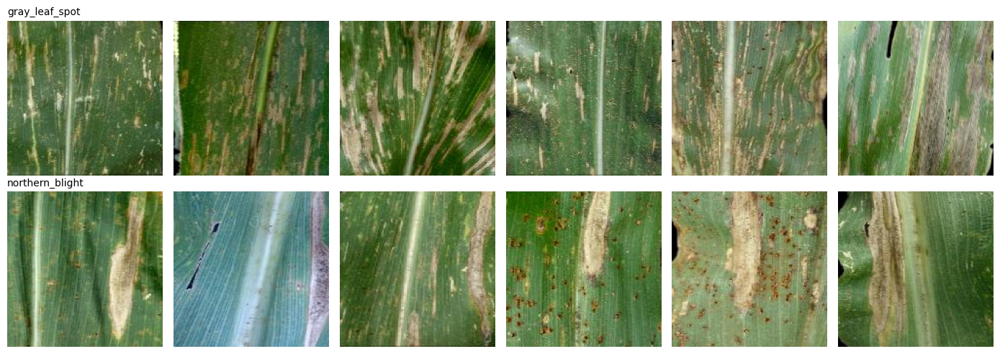

In [ ]:
def valid_boxes(p, size, stride=16, max_black=0.01, thr=30):
    """Esquinas (y, x) de recortes size x size con <= max_black de píxeles negros (huecos incluidos)."""
    a = np.asarray(Image.open(p).convert("RGB"))
    dark = (a.max(axis=2) < thr).astype(np.int32)
    ii = np.pad(dark.cumsum(0).cumsum(1), ((1, 0), (1, 0))) 
    H, W = dark.shape
    out = []
    for y in range(0, H - size + 1, stride):
        for x in range(0, W - size + 1, stride):
            black = ii[y + size, x + size] - ii[y, x + size] - ii[y + size, x] + ii[y, x]
            if black <= max_black * size * size:
                out.append((y, x))
    return out

SIZES = (96, 128, 160, 192)
rows = []
for s in SIZES:
    n = np.array([len(valid_boxes(p, s)) for p in df["seg_path"]])
    t = pd.DataFrame({"label": df["label"], "n": n})
    rows.append(pd.DataFrame({
        f"% con ≥1 recorte ({s}px)": t.groupby("label")["n"].apply(lambda v: (v > 0).mean() * 100).round(1),
        f"mediana recortes ({s}px)": t.groupby("label")["n"].median(),
    }))
print(pd.concat(rows, axis=1).T.to_string())

# ¿se ve la forma de la lesión en un recorte de 160 px?
S = 160
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r, lab in enumerate(["gray_leaf_spot", "northern_blight"]):
    shown = 0
    for p in df[df.label == lab].sample(40, random_state=2)["seg_path"]:
        b = valid_boxes(p, S)
        if not b:
            continue
        y, x = b[np.random.default_rng(shown).integers(len(b))]
        axes[r, shown].imshow(Image.open(p).convert("RGB").crop((x, y, x + S, y + S)))
        axes[r, shown].axis("off"); shown += 1
        if shown == 6:
            break
    axes[r, 0].set_title(lab, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Con **96 px** casi todas las imágenes tienen algún recorte válido (94% a 99.7%) y hay muchos recortes por imagen. Con 128 px bajan a 81%-99.6%, con 160 px a ~56%-60% en las clases enfermas y con 192 px casi no queda ninguno (16%-33%). Mientras más grande el recorte, más imágenes se pierden, **sobre todo de las clases enfermas**, lo que sesgaría los datos.

# **<font color= #7aa8a7> 6. Split train / val / test </font>**
Se divide 70% / 15% / 15% con estas reglas:
- Se reparten **grupos completos** (una hoja y sus copias siempre quedan juntas).
- Se reparte **por clase**, para que cada conjunto tenga las mismas proporciones.
- Se hace **antes** de cualquier aumento de datos, con semilla fija (42) para poder repetirlo.

In [ ]:
TARGET = {"train": 0.70, "val": 0.15, "test": 0.15}

# Un grupo = una clase
groups = (df.groupby("group")
            .agg(size=("path", "size"), label=("label", "first"))
            .reset_index()
            .sample(frac=1, random_state=42) # mezclar
            .sort_values("size", ascending=False, kind="stable")) # los grupos grandes primero

# Cuántas imágenes le faltan a cada split, por clase
need = {lab: {s: p * n for s, p in TARGET.items()} for lab, n in df["label"].value_counts().items()}

assign = {}
for _, gr in groups.iterrows():
    lab = gr["label"]
    s = max(need[lab], key=lambda k: need[lab][k])    # el split que más le falta a esa clase
    assign[gr["group"]] = s
    need[lab][s] -= gr["size"]

df["split"] = df["group"].map(assign)

print(pd.crosstab(df["label"], df["split"], margins=True)[["train", "val", "test", "All"]])
print("\nProporción por split:")
print(df["split"].value_counts(normalize=True).round(3))
print("\nProporción de clases dentro de cada split:")
print(pd.crosstab(df["split"], df["label"], normalize="index").round(3))

# Comprobación de fuga: ningún grupo en más de un split
assert (df.groupby("group")["split"].nunique() == 1).all(), "Hay grupos repartidos en varios splits"
print("\nSin fuga entre splits")

split            train  val  test   All
label                                  
common_rust        834  179   179  1192
gray_leaf_spot     359   77    77   513
healthy            814  174   174  1162
northern_blight    689  148   148   985
All               2696  578   578  3852

Proporción por split:
split
train    0.70
val      0.15
test     0.15
Name: proportion, dtype: float64

Proporción de clases dentro de cada split:
label  common_rust  gray_leaf_spot  healthy  northern_blight
split                                                       
test         0.310           0.133    0.301            0.256
train        0.309           0.133    0.302            0.256
val          0.310           0.133    0.301            0.256

Sin fuga entre splits


El split queda en **2,696 / 578 / 578** imágenes. Las proporciones de cada clase son prácticamente iguales en los tres conjuntos (por ejemplo `gray_leaf_spot` 13.3% en todos) y la celda confirma que no hay fuga entre conjuntos.

Se escribe `split_v1.csv` (un renglón por imagen con su conjunto y grupo) y se sube a S3 junto con las imágenes segmentadas. Este archivo es la **forma de organización** del split.

In [23]:
df["seg_key"] = [f"{S3_PREFIX_SEG}/{l}/{Path(p).name}" for l, p in zip(df["label"], df["seg_path"])]

cols = ["s3_key", "seg_key", "label", "split", "group", "bg_frac", "dark_frac", "dark_seg"]
csv_path = WORK / "split_v1.csv"
df[cols].to_csv(csv_path, index=False)

s3.upload_file(str(csv_path), BUCKET, "maize/splits/split_v1.csv")
run(["aws", "s3", "sync", str(SEG), f"s3://{BUCKET}/{S3_PREFIX_SEG}/",
     "--region", REGION, "--only-show-errors"])
df.to_pickle(WORK / "df_checkpoint.pkl")
# Para recuperar tras un reinicio:  df = pd.read_pickle(WORK / "df_checkpoint.pkl")

print(f"s3://{BUCKET}/maize/splits/split_v1.csv")
print(f"s3://{BUCKET}/{S3_PREFIX_SEG}/{{clase}}/")

$ aws s3 sync /home/ec2-user/maize_work/raw_segmented s3://sagemaker-maize-disease-248471876373-us-east-1/maize/raw_segmented/ --region us-east-1 --only-show-errors
s3://sagemaker-maize-disease-248471876373-us-east-1/maize/splits/split_v1.csv
s3://sagemaker-maize-disease-248471876373-us-east-1/maize/raw_segmented/{clase}/


Para cada imagen segmentada se buscan los recortes que no tocan ningún píxel negro. Se prueba primero el tamaño `PRIMARY` y, si no cabe ninguno, el de respaldo `FALLBACK`. Antes se agranda un poco el negro para no dejar pasar los bordes borrosos.

In [24]:
PRIMARY, FALLBACK = 128, 96
STRIDE = 16

def clean_integral(p, thr=30, grow=2):
    # Imagen integral del negro DILATADO: sirve para contar píxeles negros de cualquier recorte en O(1)
    a = np.asarray(Image.open(p).convert("RGB"))
    dark = ndi.binary_dilation(a.max(axis=2) < thr, iterations=grow)
    return np.pad(dark.astype(np.int32).cumsum(0).cumsum(1), ((1, 0), (1, 0)))

def boxes_from_ii(ii, size, stride=STRIDE):
    # Esquinas (y, x) de recortes size x size SIN ningún píxel negro (huecos y rebabas incluidos)
    H, W = ii.shape[0] - 1, ii.shape[1] - 1
    out = []
    for y in range(0, H - size + 1, stride):
        for x in range(0, W - size + 1, stride):
            if ii[y + size, x + size] - ii[y, x + size] - ii[y + size, x] + ii[y, x] == 0:
                out.append((y, x))
    return out

recs, used = [], []
for r in df.itertuples():
    ii = clean_integral(r.seg_path)
    size = PRIMARY
    b = boxes_from_ii(ii, size)
    if not b:                                   # respaldo: recorte más chico
        size = FALLBACK
        b = boxes_from_ii(ii, size)
    used.append(size if b else 0)
    recs += [(r.seg_key, r.label, r.split, r.group, size, y, x) for y, x in b]

df["patch_size"] = used
idx = pd.DataFrame(recs, columns=["seg_key", "label", "split", "group", "size", "y", "x"])

print("Tamaño de recorte usado por clase (% de imágenes; 0 = sin recorte válido):")
print((pd.crosstab(df["label"], df["patch_size"], normalize="index") * 100).round(1))
print("\nImágenes SIN recorte válido, por clase y split:")
print(pd.crosstab(df[df.patch_size == 0]["label"], df[df.patch_size == 0]["split"]))
print("\nRecortes por imagen (mediana):")
print(idx.groupby(["label", "seg_key"]).size().groupby("label").median())

# Comprobación: ningún recorte del índice toca un píxel negro (se mira en la imagen original, sin dilatar)
chk = idx.sample(min(300, len(idx)), random_state=0)
path_of = dict(zip(df["seg_key"], df["seg_path"]))
for r in chk.itertuples():
    a = np.asarray(Image.open(path_of[r.seg_key]).convert("RGB"))
    assert (a[r.y:r.y + r.size, r.x:r.x + r.size].max(axis=2) >= 30).all()
print("\nComprobación OK: sin píxeles negros en los recortes muestreados")

idx_path = WORK / "patch_index_v1.csv"
idx.to_csv(idx_path, index=False)
s3.upload_file(str(idx_path), BUCKET, "maize/splits/patch_index_v1.csv")
df.to_pickle(WORK / "df_checkpoint.pkl")
print(f"s3://{BUCKET}/maize/splits/patch_index_v1.csv  ({len(idx):,} recortes)")

Tamaño de recorte usado por clase (% de imágenes; 0 = sin recorte válido):
patch_size        0     96    128
label                            
common_rust       3.4  22.6  74.0
gray_leaf_spot   13.1  33.7  53.2
healthy           0.5   0.1  99.4
northern_blight  13.7  27.1  59.2

Imágenes SIN recorte válido, por clase y split:
split            test  train  val
label                            
common_rust         5     32    4
gray_leaf_spot      7     53    7
healthy             1      4    1
northern_blight    24     87   24

Recortes por imagen (mediana):
label
common_rust        10.0
gray_leaf_spot      8.0
healthy            81.0
northern_blight    10.0
dtype: float64

Comprobación OK: sin píxeles negros en los recortes muestreados
s3://sagemaker-maize-disease-248471876373-us-east-1/maize/splits/patch_index_v1.csv  (122,535 recortes)


Hay imágenes que no tienen ningún recorte válido (sobre todo de `northern_blight`), esas **no se usan**.